ACTIVITY 1


In [1]:
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Activity 1.1: Data Preparation

# Create a sample dataset of 100 customers
np.random.seed(42)

data = {
    'Age': np.random.randint(20, 60, 100),
    'PurchaseFrequency': np.random.uniform(0.5, 5, 100).round(1),
    'RespondedToCampaign': np.random.choice(
        [0, 1], 100, p=[0.6, 0.4]
    )
}

# Make campaign response dependent on customer behavior
for i in range(100):
    if data['Age'][i] < 35 and data['PurchaseFrequency'][i] > 3:
        data['RespondedToCampaign'][i] = 1
    elif data['Age'][i] > 50 and data['PurchaseFrequency'][i] < 1.5:
        data['RespondedToCampaign'][i] = 0

# Convert the data into a DataFrame
df = pd.DataFrame(data)

# Separate features (X) and target (y)
X = df[['Age', 'PurchaseFrequency']]
y = df['RespondedToCampaign']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Campaign Response Data (X_train head):")
print(X_train.head())

print("\nCampaign Response Target (y_train head):")
print(y_train.head())

# Activity 1.2: Decision Tree Training

# Create the Decision Tree classifier
model = DecisionTreeClassifier(max_depth=3, random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict responses for test data
y_pred = model.predict(X_test)

# Calculate and display accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nActual Test Values:")
print(y_test.to_numpy())

print("\nPredicted Values:")
print(y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

Campaign Response Data (X_train head):
    Age  PurchaseFrequency
11   55                4.0
47   54                2.4
85   30                0.7
28   35                1.2
93   47                3.6

Campaign Response Target (y_train head):
11    0
47    1
85    0
28    1
93    1
Name: RespondedToCampaign, dtype: int64

Actual Test Values:
[1 0 0 1 0 0 0 0 1 0 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 1 0 1 1 0]

Predicted Values:
[1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0]

Model Accuracy: 60.00%


ACTIVITY 2

Spam Detection Data (X_train head):
    NumSuspiciousKeywords
11                      7
47                      3
85                      7
28                      6
93                      9

Spam Target (y_train head):
11    1
47    0
85    1
28    1
93    1
Name: IsSpam, dtype: int64

Actual Test Values:
[0 0 1 0 1 0 1 0 0 1 1 1 0 0 0 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0]

Predicted Values:
[0 0 1 0 1 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0]

Model Accuracy: 96.67%


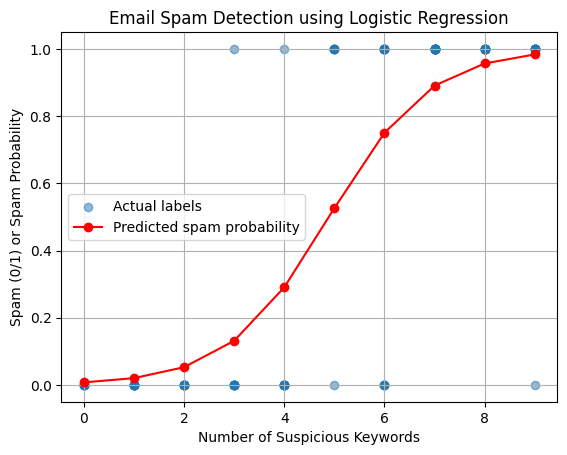

In [2]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Activity 2.1: Data Preparation
np.random.seed(42)

# Generate suspicious keyword counts for 100 emails
keywords = np.random.randint(0, 10, 100)

# Calculate spam probabilities using the sigmoid function
spam_prob = 1 / (1 + np.exp(-(keywords - 5)))

# Generate binary spam labels
is_spam = (np.random.rand(100) < spam_prob).astype(int)

# Create the dataset
df = pd.DataFrame({
    'NumSuspiciousKeywords': keywords,
    'IsSpam': is_spam
})

# Separate features and target
X = df[['NumSuspiciousKeywords']]
y = df['IsSpam']

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print("Spam Detection Data (X_train head):")
print(X_train.head())

print("\nSpam Target (y_train head):")
print(y_train.head())

# Activity 2.2: Logistic Regression Training
model = LogisticRegression()

# Train the model
model.fit(X_train, y_train)

# Predict spam labels for test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nActual Test Values:")
print(y_test.to_numpy())

print("\nPredicted Values:")
print(y_pred)

print("\nModel Accuracy: {:.2f}%".format(accuracy * 100))

# Optional: Visualize the data and model probabilities
plt.scatter(
    X['NumSuspiciousKeywords'],
    y,
    alpha=0.5,
    label='Actual labels'
)

keyword_range = pd.DataFrame({
    'NumSuspiciousKeywords': np.arange(0, 10)
})

spam_predictions = model.predict_proba(keyword_range)[:, 1]

plt.plot(
    keyword_range['NumSuspiciousKeywords'],
    spam_predictions,
    color='red',
    marker='o',
    label='Predicted spam probability'
)

plt.xlabel('Number of Suspicious Keywords')
plt.ylabel('Spam (0/1) or Spam Probability')
plt.title('Email Spam Detection using Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()